# Thực nghiệm đủ 7 cấu hình pretrained
Tất cả code nằm trong notebook này, không cần file `.py` nào.

Cài ở root: `uv pip install -r requirements_learned.txt`; chọn kernel `.venv` rồi Run All.
SIFT+BF, ORB+BF, SIFT+LightGlue, SuperPoint+LightGlue, XFeat+MNN, XFeat+LighterGlue, EfficientLoFTR.

Hai tầng thực nghiệm trên cùng một lần chạy:
1. **Tầng cặp frame** — đo chất lượng khớp trên vài cặp liên tiếp (matches, inliers, RMSE, thời gian).
2. **Tầng mosaic** — nối chuỗi tuần tự, tích luỹ H về frame đầu, warp/blend ra một bảng đồ hoàn chỉnh cho **từng** cấu hình.

Pilot mặc định: 3 cặp đầu mỗi sequence cho tầng cặp; chuỗi 20 frame đầu cho tầng mosaic; CPU 4 threads; tối đa 640 px; kích thước chia hết 32. Sparse tối đa 2.000 điểm; EfficientLoFTR semi-dense không ép về số điểm sparse.
Không train, chỉ dùng checkpoint công khai. Tải lần đầu cần mạng. SuperPoint dùng theo giấy phép nghiên cứu phi thương mại của Magic Leap.

Mỗi run ghi vào thư mục riêng theo UTC: `pairs/` cho tầng cặp, `mosaic/` cho tầng bảng đồ, kèm cấu hình + hash ảnh nguồn. Run mới không ghi đè run trước.

**Giới hạn quan trọng:** có mosaic **không** nghĩa là đã đo drift — chưa so với `trajectory.txt`. RMSE inlier chỉ chẩn đoán nội bộ phép fit. `canvas_covered_fraction` là tỷ lệ pixel canvas có ảnh, **không phải** diện tích mặt đất. Blend là trộn tuần tự 50/50, chưa phải seam-line. Thời gian là một lượt sau warmup, không đủ kết luận benchmark.
Nguồn: XFeat (verlab/accelerated_features), LightGlue (cvg/LightGlue), EfficientLoFTR (zju3dv/EfficientLoFTR), bản Transformers `zju-community/efficientloftr`.

In [1]:
import csv
import gc
import hashlib
import html
import json
import platform
import time
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import cv2
import numpy as np
import torch
from IPython.display import FileLink, display
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "requirements.txt").exists() else Path.cwd().parent
SEQUENCES = ("phantom3-village-kfs", "phantom3-grass-kfs")
PAIRS = 3
MAX_SIDE = 640
MOSAIC_FRAMES = 20        # số frame nối thành một bảng đồ
DEVICE = "cpu"  # đổi thành "cuda" nếu kernel có CUDA; không âm thầm fallback
print("Root:", ROOT)

Root: d:\fptu\_hoc-lieu\ky4\cvprj


### 1. Adapter cho 7 cấu hình
Mỗi adapter nhận 2 ảnh RGB `uint8` và trả 2 mảng toạ độ đã ghép cặp trong hệ pixel ảnh đầu vào. Không có bước huấn luyện.

In [2]:
XFEAT_REV = "e92685f57f8318b18725c5c8c0bd28c7fe188d9a"
ELOFTR_REV = "face1a79050ffa3e9da28720d1cf93aaf2e8f421"
LIGHTGLUE_REV = "eb42fee2d71449efb0aa5c10549752b5d75384d8"

METHODS = ("sift_bf", "orb_bf", "sift_lightglue", "superpoint_lightglue",
           "xfeat_mnn", "xfeat_lighterglue", "efficientloftr")

def tensor(image, device):
    return torch.from_numpy(image.copy()).permute(2, 0, 1).float().to(device) / 255


def load_matcher(method, device, max_points=2000):
    if method not in METHODS:
        raise ValueError(method)
    if method in ("sift_bf", "orb_bf"):
        sift = method == "sift_bf"
        detector = cv2.SIFT_create(nfeatures=max_points) if sift else cv2.ORB_create(nfeatures=max_points)
        matcher = cv2.BFMatcher(cv2.NORM_L2 if sift else cv2.NORM_HAMMING)
        def match(a, b):
            k0, d0 = detector.detectAndCompute(cv2.cvtColor(a, cv2.COLOR_RGB2GRAY), None)
            k1, d1 = detector.detectAndCompute(cv2.cvtColor(b, cv2.COLOR_RGB2GRAY), None)
            if d0 is None or d1 is None or len(d1) < 2:
                return np.empty((0, 2)), np.empty((0, 2))
            good = [m for pair in matcher.knnMatch(d0, d1, k=2) if len(pair) == 2
                    for m, n in [pair] if m.distance < 0.75 * n.distance]
            return (np.float32([k0[m.queryIdx].pt for m in good]).reshape(-1, 2),
                    np.float32([k1[m.trainIdx].pt for m in good]).reshape(-1, 2))
        return match
    if method in ("sift_lightglue", "superpoint_lightglue"):
        from lightglue import SIFT, SuperPoint, LightGlue
        from lightglue.utils import rbd
        sift = method == "sift_lightglue"
        extractor = (SIFT(max_num_keypoints=max_points, backend="opencv", rootsift=True) if sift
                     else SuperPoint(max_num_keypoints=max_points)).eval().to(device)
        matcher = LightGlue(features="sift" if sift else "superpoint").eval().to(device)
        extractor.requires_grad_(False)
        matcher.requires_grad_(False)
        @torch.inference_mode()
        def match(a, b):
            f0 = extractor.extract(tensor(a, device), resize=None)
            f1 = extractor.extract(tensor(b, device), resize=None)
            if min(f0["keypoints"].shape[1], f1["keypoints"].shape[1]) == 0:
                return np.empty((0, 2)), np.empty((0, 2))
            idx = rbd(matcher({"image0": f0, "image1": f1}))["matches"]
            return (rbd(f0)["keypoints"][idx[:, 0]].cpu().numpy(),
                    rbd(f1)["keypoints"][idx[:, 1]].cpu().numpy())
        return match
    if method.startswith("xfeat"):
        model = torch.hub.load(f"verlab/accelerated_features:{XFEAT_REV}", "XFeat",
                               pretrained=False, top_k=max_points, trust_repo=True)
        weights = torch.hub.load_state_dict_from_url(
            f"https://raw.githubusercontent.com/verlab/accelerated_features/{XFEAT_REV}/weights/xfeat.pt",
            file_name=f"xfeat_{XFEAT_REV}.pt", map_location=device)
        model.net.load_state_dict(weights)
        model.dev = torch.device(device)
        model.to(device).eval().requires_grad_(False)
        if method == "xfeat_lighterglue":
            from modules.lighterglue import LighterGlue
            model.lighterglue = LighterGlue().to(device).eval().requires_grad_(False)
        @torch.inference_mode()
        def match(a, b):
            f0 = model.detectAndCompute(tensor(a, device)[None])[0]
            f1 = model.detectAndCompute(tensor(b, device)[None])[0]
            if min(len(f0["keypoints"]), len(f1["keypoints"])) == 0:
                return np.empty((0, 2)), np.empty((0, 2))
            if method == "xfeat_lighterglue":
                f0["image_size"], f1["image_size"] = a.shape[1::-1], b.shape[1::-1]
                return model.match_lighterglue(f0, f1)[:2]
            i, j = model.match(f0["descriptors"], f1["descriptors"])
            return f0["keypoints"][i].cpu().numpy(), f1["keypoints"][j].cpu().numpy()
        return match
    from transformers import AutoImageProcessor, AutoModelForKeypointMatching
    source = "zju-community/efficientloftr"
    processor = AutoImageProcessor.from_pretrained(source, revision=ELOFTR_REV)
    model = AutoModelForKeypointMatching.from_pretrained(source, revision=ELOFTR_REV).eval().to(device)
    model.requires_grad_(False)
    @torch.inference_mode()
    def match(a, b):
        inputs = processor([a, b], do_resize=False, return_tensors="pt").to(device)
        output = processor.post_process_keypoint_matching(
            model(**inputs), [[a.shape[:2], b.shape[:2]]], threshold=0.2)[0]
        return output["keypoints0"].cpu().numpy(), output["keypoints1"].cpu().numpy()
    return match

### 2. Tiện ích: đọc ảnh, ghi JSON nghiêm ngặt, ước lượng H
`geometry()` là nơi chấp nhận/từ chối một cặp: đủ 4 điểm, H hữu hạn và hạng 3.

In [3]:
def dump(path, value):
    """Ghi JSON nghiêm ngặt: từ chối NaN/Infinity để không sinh file JSON không hợp lệ."""
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
def image(path, max_side):
    bgr = cv2.imread(str(path))
    if bgr is None:

        raise ValueError(f"Unreadable image: {path}")
    h, w = bgr.shape[:2]
    scale = min(1, max_side / max(h, w))
    size = (max(32, int(w * scale) // 32 * 32), max(32, int(h * scale) // 32 * 32))
    return cv2.cvtColor(cv2.resize(bgr, size, interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)


def geometry(p0, p1):
    H, mask = (cv2.findHomography(p1, p0, cv2.RANSAC, 3.0) if len(p0) >= 4 else (None, None))
    good = np.zeros(len(p0), bool)
    rmse = None
    if H is not None and mask is not None and np.isfinite(H).all() and np.linalg.matrix_rank(H) == 3:
        good = mask.ravel().astype(bool)
        if good.sum() >= 4:
            predicted = cv2.perspectiveTransform(p1[good].reshape(-1, 1, 2), H).reshape(-1, 2)
            value = float(np.sqrt(np.mean(np.sum((predicted - p0[good]) ** 2, axis=1))))
            rmse = value if np.isfinite(value) else None
    return H if rmse is not None else None, good, rmse

### 3. DỰNG FULL BẢNG ĐỒ (mosaic) — phần chính
`canvas_and_mosaic()` tính canvas chung rồi warp/blend tuần tự, **cùng cách với notebook 01** (mask hình học, trộn 50/50).
`build_mosaic()` nối chuỗi tới `MOSAIC_FRAMES` frame, dừng ngay ở cặp lỗi đầu tiên, tích luỹ $H_{i \to 0}$.
Mỗi cấu hình cho ra một `mosaic.png` + `metrics.json` (kích thước canvas, độ phủ, chuỗi cặp, lý do dừng nếu có).

In [4]:
def canvas_and_mosaic(images, homographies, max_dim=5000):
    """Warp/blend tuần tự lên canvas chung, cùng cách làm với notebook 01."""
    corners_all = []
    for img, H in zip(images, homographies):
        h, w = img.shape[:2]
        corners = np.array([[0, 0], [w, 0], [w, h], [0, h]], np.float32).reshape(-1, 1, 2)
        corners_all.append(cv2.perspectiveTransform(corners, H).reshape(-1, 2))
    pts = np.vstack(corners_all)
    if not np.isfinite(pts).all():
        raise ValueError("Canvas corners are not finite")
    min_x, min_y = np.floor(pts.min(axis=0)).astype(int)
    max_x, max_y = np.ceil(pts.max(axis=0)).astype(int)
    width, height = max(1, int(max_x - min_x)), max(1, int(max_y - min_y))
    scale = min(1.0, max_dim / max(width, height))
    out_w, out_h = max(1, int(width * scale)), max(1, int(height * scale))
    S = np.diag([scale, scale, 1.0])
    T = np.array([[1.0, 0.0, -min_x], [0.0, 1.0, -min_y], [0.0, 0.0, 1.0]])

    mosaic = np.zeros((out_h, out_w, 3), np.uint8)
    covered = np.zeros((out_h, out_w), bool)
    H_to_mosaic = []
    for img, H in zip(images, homographies):
        full = S @ T @ H
        H_to_mosaic.append(full)
        warped = cv2.warpPerspective(img, full, (out_w, out_h))
        ones = np.ones(img.shape[:2], np.float32)
        mask = cv2.warpPerspective(ones, full, (out_w, out_h)) > 0.5
        first = mask & ~covered
        mosaic[first] = warped[first]
        blend = mask & covered
        if blend.any():
            mosaic[blend] = (0.5 * mosaic[blend].astype(np.float32)
                             + 0.5 * warped[blend].astype(np.float32)).astype(np.uint8)
        covered |= mask
    return mosaic, H_to_mosaic, float(covered.mean()), (out_w, out_h)


def build_mosaic(matcher, method, sequence, frames, limit):
    """Nối chuỗi tuần tự tới `limit` frame; dừng ngay ở cặp lỗi đầu tiên."""
    images = [a for _, a in frames[:limit]]
    chain = []
    H_accum = [np.eye(3, dtype=np.float64)]
    for i in range(1, len(images)):
        started = time.perf_counter()
        p0, p1 = matcher(images[i - 1], images[i])
        seconds = time.perf_counter() - started
        p0, p1 = np.asarray(p0, np.float32).reshape(-1, 2), np.asarray(p1, np.float32).reshape(-1, 2)
        if p0.shape != p1.shape or not np.isfinite(p0).all() or not np.isfinite(p1).all():
            raise ValueError(f"Invalid correspondences: {method}")
        cv2.setRNGSeed(0)
        H, good, rmse = geometry(p0, p1)
        ok = H is not None
        chain.append(dict(pair=i, status="success" if ok else "failed", matches=len(p0),
                          inliers=int(good.sum()), rmse_px=rmse, match_seconds=seconds))
        if not ok:
            print(f"  {method} {sequence}: cặp {i} thất bại -> dừng chuỗi ở {len(H_accum)} frame", flush=True)
            break
        H_accum.append(H_accum[-1] @ H)
    stitched = len(H_accum)
    mosaic, H_to_mosaic, covered, size = canvas_and_mosaic(images[:stitched], H_accum)
    return mosaic, H_to_mosaic, covered, size, chain, stitched

### 4. Pipeline chạy: tầng cặp frame rồi tầng mosaic
Với mỗi cấu hình: chạy 3 cặp đầu (`pairs/`) → dựng bảng đồ `MOSAIC_FRAMES` frame (`mosaic/`).

In [5]:
def run(root, sequences=("phantom3-village-kfs", "phantom3-grass-kfs"), pairs=3, max_side=640,
        device="cpu", mosaic_frames=20):
    root = Path(root)
    if pairs < 1 or mosaic_frames < 2 or max_side < 32:
        raise ValueError("pairs >= 1, mosaic_frames >= 2, max_side >= 32 required")
    if device.startswith("cuda") and not torch.cuda.is_available():
        raise RuntimeError("CUDA unavailable")
    torch.set_num_threads(4)
    cv2.setNumThreads(4)
    torch.manual_seed(0)
    target = root / "notebooks" / "outputs" / "03_all_models" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    target.mkdir(parents=True, exist_ok=False)
    manifest = {"device": device, "platform": platform.platform(), "torch": torch.__version__,
                "opencv": cv2.__version__, "methods": list(METHODS), "sequences": list(sequences),
                "pairs_per_sequence": pairs, "mosaic_frames_requested": mosaic_frames,
                "max_side": max_side, "max_keypoints": 2000,
                "resize": "common resize: dimensions rounded down to multiples of 32",
                "seed": 0, "cpu_threads": 4, "ransac_px": 3.0, "bf_ratio": 0.75,
                "eloftr_confidence": 0.2, "xfeat_revision": XFEAT_REV, "eloftr_revision": ELOFTR_REV,
                "lightglue_revision": LIGHTGLUE_REV,
                "scope": "pair pilot + sequential mosaic; no drift/ground-truth evaluation; EfficientLoFTR exploratory",
                "timing": "warm matching includes preprocessing, extraction, point transfer; excludes IO, setup, warmup, RANSAC, rendering",
                "inputs": []}
    need = max(pairs, mosaic_frames - 1)
    datasets = {}
    for sequence in sequences:
        dirs = list((root / "data" / sequence).rglob("rgb"))
        if len(dirs) != 1:
            raise ValueError(f"Expected exactly one rgb folder: {sequence}")
        files = sorted(dirs[0].glob("*.jpg"), key=lambda p: float(p.stem))[:need + 1]
        if len(files) != need + 1:
            raise ValueError(f"Insufficient frames: {sequence}")
        datasets[sequence] = [(p, image(p, max_side)) for p in files]
        manifest["inputs"].extend({"path": str(p.relative_to(root)), "sha256": hashlib.sha256(p.read_bytes()).hexdigest(),
                                    "processed_hw": list(a.shape[:2])} for p, a in datasets[sequence])
    dump(target / "manifest.json", manifest)

    rows, mosaic_rows = [], []
    def sync():
        if device.startswith("cuda"):
            torch.cuda.synchronize()

    for method in METHODS:
        started = time.perf_counter()
        matcher = load_matcher(method, device)
        sync()
        setup = time.perf_counter() - started
        first = next(iter(datasets.values()))
        matcher(first[0][1], first[1][1])  # warmup excluded from measured calls
        sync()

        for sequence, frames in datasets.items():
            folder = target / "pairs" / sequence / method
            folder.mkdir(parents=True)
            metrics = []
            for i in range(pairs):
                (path0, a), (path1, b) = frames[i:i + 2]
                sync()
                started = time.perf_counter()
                p0, p1 = matcher(a, b)
                sync()
                seconds = time.perf_counter() - started
                p0, p1 = np.asarray(p0, np.float32).reshape(-1, 2), np.asarray(p1, np.float32).reshape(-1, 2)
                if p0.shape != p1.shape or not np.isfinite(p0).all() or not np.isfinite(p1).all():
                    raise ValueError(f"Invalid correspondences: {method}")
                cv2.setRNGSeed(0)
                H, good, rmse = geometry(p0, p1)
                row = dict(sequence=sequence, method=method, pair=i, status="success" if H is not None else "failed",
                           matches=len(p0), inliers=int(good.sum()), rmse_px=rmse, match_seconds=seconds)
                rows.append(row)
                metrics.append(dict(row, image0=path0.name, image1=path1.name, setup_seconds=setup,
                                    H_current_to_previous=H.tolist() if H is not None else None))
                np.savez_compressed(folder / f"pair_{i:03d}.npz", points0=p0, points1=p1, inliers=good)
                k0 = [cv2.KeyPoint(float(x), float(y), 1) for x, y in p0]
                k1 = [cv2.KeyPoint(float(x), float(y), 1) for x, y in p1]
                links = [cv2.DMatch(int(j), int(j), 0) for j in np.flatnonzero(good)[:60]]
                view = cv2.drawMatches(cv2.cvtColor(a, cv2.COLOR_RGB2BGR), k0,
                                      cv2.cvtColor(b, cv2.COLOR_RGB2BGR), k1, links, None, flags=2)
                if not cv2.imwrite(str(folder / f"pair_{i:03d}.jpg"), view):
                    raise OSError(folder)
                print(f"pair  {method} {sequence} {i} {row['status']} {len(p0)} {int(good.sum())} {seconds:.3f}s", flush=True)
            dump(folder / "metrics.json", metrics)

            started = time.perf_counter()
            mosaic, H_to_mosaic, covered, size, chain, stitched = build_mosaic(
                matcher, method, sequence, frames, mosaic_frames)
            total = time.perf_counter() - started
            folder = target / "mosaic" / sequence / method
            folder.mkdir(parents=True)
            if not cv2.imwrite(str(folder / "mosaic.png"), cv2.cvtColor(mosaic, cv2.COLOR_RGB2BGR)):
                raise OSError(folder)
            dump(folder / "metrics.json", {
                "sequence": sequence, "method": method,
                "frames_requested": mosaic_frames, "frames_stitched": stitched,
                "stopped_at_pair": chain[-1]["pair"] if chain and chain[-1]["status"] == "failed" else None,
                "canvas_width": size[0], "canvas_height": size[1],
                "canvas_covered_fraction": covered,
                "chain_total_seconds": total,
                "H_to_mosaic": [m.tolist() for m in H_to_mosaic],
                "chain": chain})
            mosaic_rows.append(dict(sequence=sequence, method=method, frames_requested=mosaic_frames,
                                    frames_stitched=stitched, canvas_width=size[0], canvas_height=size[1],
                                    canvas_covered_fraction=covered, chain_total_seconds=total))
            print(f"mosaic {method} {sequence} {stitched}/{mosaic_frames} frame | "
                  f"{size[0]}x{size[1]} | phủ {covered*100:.1f}% | {total:.1f}s", flush=True)
        del matcher
        gc.collect()
        if device.startswith("cuda"):
            torch.cuda.empty_cache()

    with (target / "summary.csv").open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    with (target / "mosaic_summary.csv").open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(mosaic_rows[0]))
        writer.writeheader()
        writer.writerows(mosaic_rows)
    write_reports(target, sequences, rows, mosaic_rows)
    return target, rows, mosaic_rows

### 5. Sinh báo cáo HTML
`write_reports()` được `run()` gọi ở cuối: bảng tầng cặp, bảng tầng mosaic, ảnh mosaic từng cấu hình và trang mục lục.
`rebuild()` sinh lại báo cáo từ một run đã xong mà không phải chạy lại inference.

In [6]:
def write_reports(target, sequences, rows, mosaic_rows):
    """Ghi trang của run và trang mục lục của notebooks/outputs."""
    target = Path(target)
    body = ["<!doctype html><meta charset='utf-8'><title>Model pilot</title>",
            "<h1>Pilot 7 cấu hình</h1>",
            "<p>Toạ độ và RMSE ở hệ pixel ảnh đã resize. RMSE inlier là chẩn đoán nội bộ phép fit, không phải ground truth hay drift. "
            "Thời gian là một lượt sau warmup, không phải benchmark.</p>",
            "<p><a href='../../index.html'>← tất cả lần chạy</a> | <a href='summary.csv'>CSV tầng cặp</a> | "
            "<a href='mosaic_summary.csv'>CSV tầng mosaic</a> | <a href='manifest.json'>Cấu hình và hash ảnh nguồn</a></p>"]

    body.append("<h2>Tầng 1 — so khớp cặp frame</h2>")
    for sequence in sequences:
        body.append(f"<h3>{html.escape(sequence)}</h3><table border='1' cellpadding='6'>"
                    "<tr><th>Cấu hình</th><th>H hợp lệ / số cặp</th><th>Thời gian match trung bình (s)</th>"
                    "<th>RMSE inlier trung bình (px, chỉ ca thành công)</th></tr>")
        for method in METHODS:
            group = [r for r in rows if r["sequence"] == sequence and r["method"] == method]
            valid = [r["rmse_px"] for r in group if r["rmse_px"] is not None]
            rmse_text = f"{np.mean(valid):.3f}" if valid else "N/A"
            body.append(f"<tr><td><a href='pairs/{sequence}/{method}/metrics.json'>{method}</a></td>"
                        f"<td>{len(valid)}/{len(group)}</td>"
                        f"<td>{np.mean([r['match_seconds'] for r in group]):.3f}</td><td>{rmse_text}</td></tr>")
        body.append("</table>")
        for method in METHODS:
            body.append(f"<h4>{method} — cặp đầu, tối đa 60 inlier</h4>"
                        f"<img style='max-width:100%' src='pairs/{sequence}/{method}/pair_000.jpg'>")

    body.append("<h2>Tầng 2 — mosaic nối chuỗi tuần tự</h2>")
    for sequence in sequences:
        body.append(f"<h3>{html.escape(sequence)}</h3><table border='1' cellpadding='6'>"
                    "<tr><th>Cấu hình</th><th>Frame ghép được</th><th>Canvas</th>"
                    "<th>Phủ canvas</th><th>Tổng thời gian (s)</th></tr>")
        for method in METHODS:
            group = [r for r in mosaic_rows if r["sequence"] == sequence and r["method"] == method]
            for r in group:
                body.append(f"<tr><td><a href='mosaic/{sequence}/{method}/metrics.json'>{method}</a></td>"
                            f"<td>{r['frames_stitched']}/{r['frames_requested']}</td>"
                            f"<td>{r['canvas_width']}x{r['canvas_height']}</td>"
                            f"<td>{r['canvas_covered_fraction']*100:.1f}%</td>"
                            f"<td>{r['chain_total_seconds']:.1f}</td></tr>")
        body.append("</table>")
        body.append("<p><b>Lưu ý:</b> phủ canvas là tỷ lệ pixel canvas có ảnh, không phải diện tích mặt đất. "
                    "Blend là trộn tuần tự 50/50, chưa phải seam-line. Chưa đối chiếu trajectory.txt nên chưa đo được drift.</p>")
        for method in METHODS:
            body.append(f"<h4>{method}</h4><img style='max-width:100%' "
                        f"src='mosaic/{sequence}/{method}/mosaic.png'>")
    (target / "index.html").write_text("\n".join(body), encoding="utf-8")
    (Path(target).parent.parent / "index.html").write_text(navigation(Path(target).parent), encoding="utf-8")


def rebuild(run_dir):
    """Sinh lại trang báo cáo từ một run đã xong, không chạy lại inference."""
    run_dir = Path(run_dir)
    manifest = json.loads((run_dir / "manifest.json").read_text(encoding="utf-8"))
    fields = ("sequence", "method", "pair", "status", "matches", "inliers", "rmse_px", "match_seconds")
    rows = [{k: item[k] for k in fields}
            for metrics in sorted(run_dir.glob("pairs/*/*/metrics.json"))
            for item in json.loads(metrics.read_text(encoding="utf-8"))]
    mosaic_rows = []
    for metrics in sorted(run_dir.glob("mosaic/*/*/metrics.json")):
        data = json.loads(metrics.read_text(encoding="utf-8"))
        mosaic_rows.append({k: data[k] for k in ("sequence", "method", "frames_requested", "frames_stitched",
                                                 "canvas_width", "canvas_height", "canvas_covered_fraction",
                                                 "chain_total_seconds")})
    write_reports(run_dir, tuple(manifest["sequences"]), rows, mosaic_rows)
    return run_dir


def navigation(runs_dir):
    """Trang mục lục notebooks/outputs: run mới nhất trước, rồi kết quả notebook 01/02."""
    def run_label(path):
        text = path.name[:8]
        stamp = f"{text[:4]}-{text[4:6]}-{text[6:8]} {path.name[9:15]} UTC"
        status = "hoàn tất" if (path / "index.html").exists() else "dở dang"
        return stamp, status
    ordered = sorted((p for p in runs_dir.iterdir() if p.is_dir()), reverse=True)
    rows = []
    for path in ordered:
        stamp, status = run_label(path)
        label = f"{runs_dir.name}/{path.name}/index.html" if status == "hoàn tất" else None
        cell = f"<a href='{label}'>{stamp}</a>" if label else f"{stamp} (dở dang)"
        rows.append(f"<tr><td>{cell}</td><td>{status}</td></tr>")
    root = runs_dir.parent
    notebook_rows = []
    ad_hoc = [p for p in sorted(root.iterdir())
              if p.is_dir() and p.name not in (runs_dir.name, "03_all_models")]
    for path in ad_hoc:
        name = path.name
        notebook_rows.append(f"<tr><td>{name}</td><td><a href='{name}/'>{name}/</a></td></tr>")
    steps = ["<li><b>Mosaic 7 cấu hình:</b> mở run mới nhất, xem mục <i>Tầng 2 — mosaic</i>.</li>",
             "<li><b>Cặp frame:</b> mục <i>Tầng 1</i> cùng trang, kèm CSV riêng cho từng tầng.</li>",
             "<li><b>Ad-hoc:</b> mỗi notebook 01/02 ghi vào thư mục cùng tên, ngay cạnh <code>03_all_models/</code>.</li>",
             "<li><b>Provenance:</b> mỗi run có <code>manifest.json</code> ghi phiên bản model, hash ảnh nguồn và cấu hình đo.</li>",
             "<li><b>Giới hạn:</b> chưa so <code>trajectory.txt</code> nên chưa có drift; RMSE inlier không phải ground truth.</li>"]
    return "\n".join([
        "<!doctype html><meta charset='utf-8'><title>notebooks/outputs</title>",
        "<h1>notebooks/outputs</h1>",
        "<p>Thư mục này bị gitignore. Mọi lần chạy đều ghi vào thư mục con riêng, không ghi đè kết quả cũ.</p>",
        "<h2>Bắt đầu từ đâu</h2><ol>" + "".join(steps) + "</ol>",
        "<h2>03_all_models — các lần chạy</h2><table border='1' cellpadding='6'>",
        "<tr><th>Lần chạy</th><th>Trạng thái</th></tr>",
        "".join(rows) if rows else "<tr><td colspan='2'>Chưa có run nào.</td></tr>",
        "</table><p>Mỗi lần chạy trong <code>03_all_models/&lt;UTC&gt;/</code>: <code>pairs/&lt;sequence&gt;/&lt;model&gt;/</code> và <code>mosaic/&lt;sequence&gt;/&lt;model&gt;/</code>.</p>",
        "<h2>Kết quả notebook 01 / 02</h2><table border='1' cellpadding='6'>",
        "<tr><th>Notebook</th><th>Kết quả</th></tr>",
        "".join(notebook_rows) if notebook_rows else "<tr><td colspan='2'>Chưa có kết quả.</td></tr>",
        "</table>"])

### 6. Chạy pilot

In [7]:
run_dir, rows, mosaic_rows = run(ROOT, sequences=SEQUENCES, pairs=PAIRS, max_side=MAX_SIDE,
                                 device=DEVICE, mosaic_frames=MOSAIC_FRAMES)
print("Mở báo cáo:", run_dir / "index.html")
print("CSV:", run_dir / "summary.csv", "|", run_dir / "mosaic_summary.csv")

pair  sift_bf phantom3-village-kfs 0 success 318 315 0.050s
pair  sift_bf phantom3-village-kfs 1 success 452 447 0.058s
pair  sift_bf phantom3-village-kfs 2 success 501 499 0.057s
mosaic sift_bf phantom3-village-kfs 20/20 frame | 647x604 | phủ 98.6% | 1.4s
pair  sift_bf phantom3-grass-kfs 0 success 54 54 0.042s
pair  sift_bf phantom3-grass-kfs 1 success 58 58 0.042s
pair  sift_bf phantom3-grass-kfs 2 success 62 62 0.042s
mosaic sift_bf phantom3-grass-kfs 20/20 frame | 648x1041 | phủ 96.9% | 1.2s
pair  orb_bf phantom3-village-kfs 0 success 602 597 0.011s
pair  orb_bf phantom3-village-kfs 1 success 740 733 0.012s
pair  orb_bf phantom3-village-kfs 2 success 918 912 0.011s
mosaic orb_bf phantom3-village-kfs 20/20 frame | 655x592 | phủ 97.0% | 0.6s
pair  orb_bf phantom3-grass-kfs 0 success 202 201 0.006s
pair  orb_bf phantom3-grass-kfs 1 success 264 262 0.006s
pair  orb_bf phantom3-grass-kfs 2 success 256 255 0.005s
mosaic orb_bf phantom3-grass-kfs 20/20 frame | 654x1056 | phủ 96.2% | 0.5s


d:\fptu\_hoc-lieu\ky4\cvprj\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


pair  sift_lightglue phantom3-village-kfs 0 success 967 948 0.453s
pair  sift_lightglue phantom3-village-kfs 1 success 1131 1118 0.383s
pair  sift_lightglue phantom3-village-kfs 2 success 1236 1235 0.384s
mosaic sift_lightglue phantom3-village-kfs 20/20 frame | 645x602 | phủ 99.0% | 8.3s
pair  sift_lightglue phantom3-grass-kfs 0 success 811 796 0.366s
pair  sift_lightglue phantom3-grass-kfs 1 success 1009 999 0.388s
pair  sift_lightglue phantom3-grass-kfs 2 success 1008 1004 0.410s
mosaic sift_lightglue phantom3-grass-kfs 20/20 frame | 651x1043 | phủ 96.5% | 7.4s
pair  superpoint_lightglue phantom3-village-kfs 0 success 728 697 0.971s
pair  superpoint_lightglue phantom3-village-kfs 1 success 861 816 0.956s
pair  superpoint_lightglue phantom3-village-kfs 2 success 964 916 0.940s
mosaic superpoint_lightglue phantom3-village-kfs 20/20 frame | 645x595 | phủ 98.2% | 18.5s
pair  superpoint_lightglue phantom3-grass-kfs 0 success 101 96 0.834s
pair  superpoint_lightglue phantom3-grass-kfs 1 su

Using cache found in C:\Users\diepq/.cache\torch\hub\verlab_accelerated_features_e92685f57f8318b18725c5c8c0bd28c7fe188d9a


pair  xfeat_mnn phantom3-village-kfs 0 success 1273 995 0.085s
pair  xfeat_mnn phantom3-village-kfs 1 success 1298 929 0.093s
pair  xfeat_mnn phantom3-village-kfs 2 success 1408 1097 0.102s
mosaic xfeat_mnn phantom3-village-kfs 20/20 frame | 650x609 | phủ 98.3% | 2.0s
pair  xfeat_mnn phantom3-grass-kfs 0 success 1074 818 0.093s
pair  xfeat_mnn phantom3-grass-kfs 1 success 1309 1099 0.093s
pair  xfeat_mnn phantom3-grass-kfs 2 success 1340 1143 0.092s
mosaic xfeat_mnn phantom3-grass-kfs 20/20 frame | 653x1057 | phủ 96.4% | 2.0s
Loaded LightGlue model


Using cache found in C:\Users\diepq/.cache\torch\hub\verlab_accelerated_features_e92685f57f8318b18725c5c8c0bd28c7fe188d9a


pair  xfeat_lighterglue phantom3-village-kfs 0 success 1040 1008 0.254s
pair  xfeat_lighterglue phantom3-village-kfs 1 success 992 937 0.249s
pair  xfeat_lighterglue phantom3-village-kfs 2 success 1154 1101 0.245s
mosaic xfeat_lighterglue phantom3-village-kfs 20/20 frame | 642x601 | phủ 99.6% | 5.1s
pair  xfeat_lighterglue phantom3-grass-kfs 0 success 876 852 0.231s
pair  xfeat_lighterglue phantom3-grass-kfs 1 success 1125 1105 0.249s
pair  xfeat_lighterglue phantom3-grass-kfs 2 success 1175 1145 0.268s
mosaic xfeat_lighterglue phantom3-grass-kfs 20/20 frame | 660x1057 | phủ 95.9% | 5.1s


d:\fptu\_hoc-lieu\ky4\cvprj\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


pair  efficientloftr phantom3-village-kfs 0 success 2655 2200 1.456s
pair  efficientloftr phantom3-village-kfs 1 success 2923 2096 1.405s
pair  efficientloftr phantom3-village-kfs 2 success 3040 3040 1.455s
mosaic efficientloftr phantom3-village-kfs 20/20 frame | 1465x626 | phủ 55.6% | 28.0s
pair  efficientloftr phantom3-grass-kfs 0 success 2415 2334 1.503s
pair  efficientloftr phantom3-grass-kfs 1 success 2812 2812 1.461s
pair  efficientloftr phantom3-grass-kfs 2 success 2812 2812 1.477s
mosaic efficientloftr phantom3-grass-kfs 20/20 frame | 946x1073 | phủ 73.4% | 28.5s
Mở báo cáo: d:\fptu\_hoc-lieu\ky4\cvprj\notebooks\outputs\03_all_models\20261013T164937_145955Z\index.html
CSV: d:\fptu\_hoc-lieu\ky4\cvprj\notebooks\outputs\03_all_models\20261013T164937_145955Z\summary.csv | d:\fptu\_hoc-lieu\ky4\cvprj\notebooks\outputs\03_all_models\20261013T164937_145955Z\mosaic_summary.csv


### 7. Hiển thị bản đồ & kiểm tra kết quả
Hiện 7 bảng đồ của một sequence ngay trong notebook, rồi kiểm tra hướng H, ca thiếu correspondence, đủ 7 cấu hình, đủ 7 mosaic mỗi sequence và JSON nghiêm ngặt.

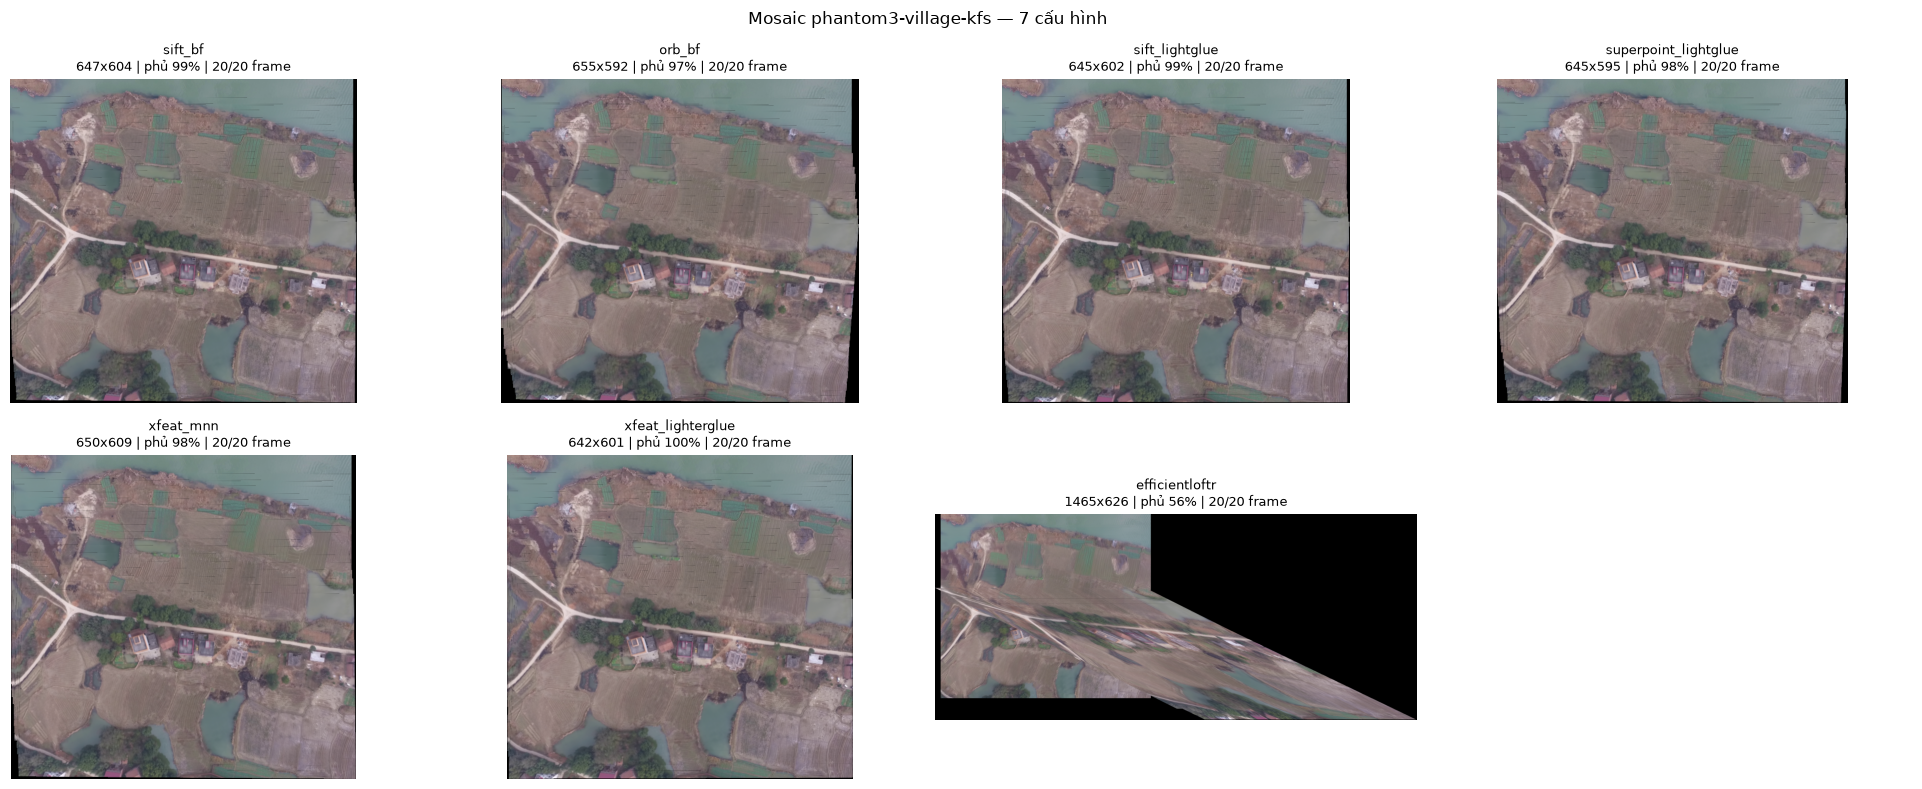

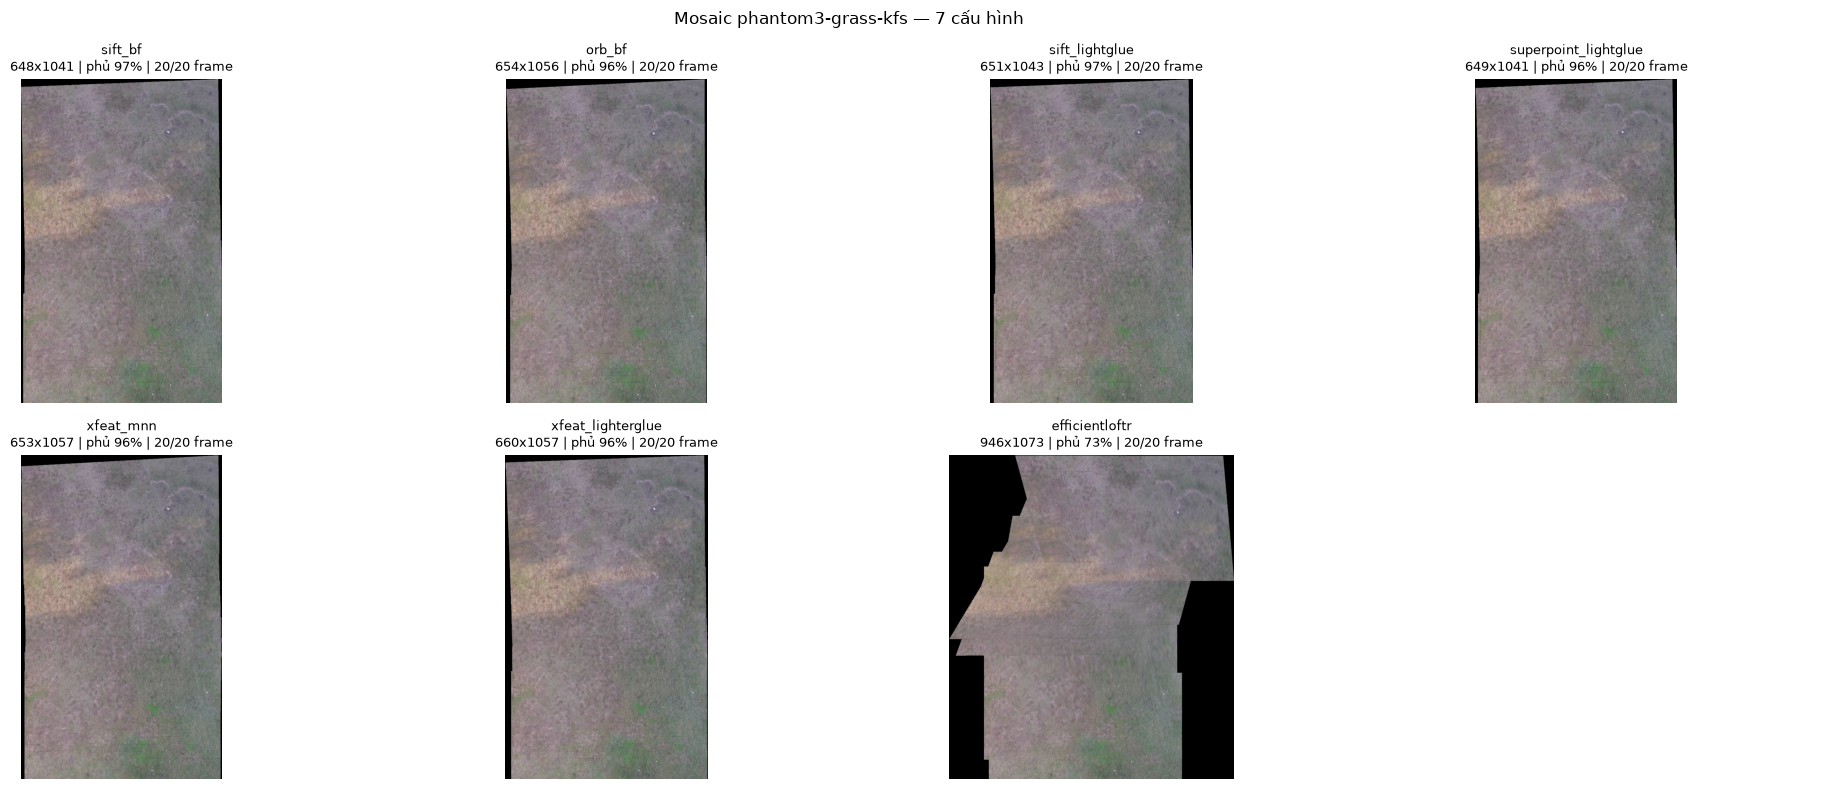

In [8]:
def show_mosaics(run_dir, sequence, methods=None, cols=4, width=5):
    """Hiển thị bản đồ của từng cấu hình để nhìn bằng mắt, không chỉ đọc số."""
    methods = methods or list(METHODS)
    files = [(m, run_dir / "mosaic" / sequence / m / "mosaic.png") for m in methods]
    missing = [str(f) for _, f in files if not f.exists()]
    assert not missing, f"Thiếu mosaic: {missing}"
    rows = -(-len(files) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(width * cols, width * rows * 0.8))
    for ax, (method, path) in zip(np.ravel(axes), files):
        img = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
        data = json.loads((path.parent / "metrics.json").read_text(encoding="utf-8"))
        ax.imshow(img)
        ax.set_title(f"{method}\n{data['canvas_width']}x{data['canvas_height']} | "
                     f"phủ {data['canvas_covered_fraction']*100:.0f}% | {data['frames_stitched']}/{data['frames_requested']} frame",
                     fontsize=9)
        ax.axis("off")
    for ax in np.ravel(axes)[len(files):]:
        ax.axis("off")
    fig.suptitle(f"Mosaic {sequence} — {len(files)} cấu hình", fontsize=12)
    plt.tight_layout()
    plt.show()


for seq in SEQUENCES:
    show_mosaics(run_dir, seq)


In [9]:
# Hướng H phải là current -> previous, sai lệch 12 px và -7 px
previous = np.float32([[0, 0], [80, 0], [80, 50], [0, 50], [20, 30], [60, 20]])
current = previous + [12, -7]
H, inliers, rmse = geometry(current.astype(np.float32), previous)
np.testing.assert_allclose(H / H[2, 2], [[1, 0, 12], [0, 1, -7], [0, 0, 1]], atol=1e-6)
assert inliers.all() and rmse < 1e-5

# Thiếu correspondence (3 điểm) phải là thất bại, không phải ước lượng bừa
H, inliers, rmse = geometry(previous[:3].astype(np.float32), current[:3])
assert H is None and not inliers.any() and rmse is None

# Tầng cặp: mọi cấu hình chạy đủ số cặp
counts = Counter(row["method"] for row in rows)
assert len(counts) == len(METHODS), counts
assert all(n == PAIRS * len(SEQUENCES) for n in counts.values()), counts

# Tầng mosaic: mỗi cấu hình phải ra một mosaic thật, phủ được canvas
assert len(mosaic_rows) == len(METHODS) * len(SEQUENCES), len(mosaic_rows)
for r in mosaic_rows:
    png = run_dir / "mosaic" / r["sequence"] / r["method"] / "mosaic.png"
    assert png.exists(), png
    img = cv2.imread(str(png))
    assert img is not None and img.shape[0] > 32 and img.shape[1] > 32, png
    assert r["frames_stitched"] >= 2, r
    assert 0 < r["canvas_covered_fraction"] <= 1, r

# Không file JSON nào chứa Infinity/NaN (JSON nghiêm ngặt)
def reject(token):
    raise ValueError(f"non-standard JSON token: {token}")
files = sorted(run_dir.rglob("*.json"))
for f in files:
    json.loads(f.read_text(encoding="utf-8"), parse_constant=reject)

print(f"PASS: hình học, {len(counts)} cấu hình, {len(rows)} cặp, {len(mosaic_rows)} mosaic, {len(files)} file JSON hợp lệ")
for r in mosaic_rows:
    print(f"  {r['method']:22} {r['sequence']:22} {r['frames_stitched']:2}/{r['frames_requested']} frame | "
          f"{r['canvas_width']}x{r['canvas_height']} | phủ {r['canvas_covered_fraction']*100:.1f}% | {r['chain_total_seconds']:.1f}s")
display(FileLink(str(run_dir / "index.html")))

PASS: hình học, 7 cấu hình, 42 cặp, 14 mosaic, 29 file JSON hợp lệ
  sift_bf                phantom3-village-kfs   20/20 frame | 647x604 | phủ 98.6% | 1.4s
  sift_bf                phantom3-grass-kfs     20/20 frame | 648x1041 | phủ 96.9% | 1.2s
  orb_bf                 phantom3-village-kfs   20/20 frame | 655x592 | phủ 97.0% | 0.6s
  orb_bf                 phantom3-grass-kfs     20/20 frame | 654x1056 | phủ 96.2% | 0.5s
  sift_lightglue         phantom3-village-kfs   20/20 frame | 645x602 | phủ 99.0% | 8.3s
  sift_lightglue         phantom3-grass-kfs     20/20 frame | 651x1043 | phủ 96.5% | 7.4s
  superpoint_lightglue   phantom3-village-kfs   20/20 frame | 645x595 | phủ 98.2% | 18.5s
  superpoint_lightglue   phantom3-grass-kfs     20/20 frame | 649x1041 | phủ 96.4% | 15.3s
  xfeat_mnn              phantom3-village-kfs   20/20 frame | 650x609 | phủ 98.3% | 2.0s
  xfeat_mnn              phantom3-grass-kfs     20/20 frame | 653x1057 | phủ 96.4% | 2.0s
  xfeat_lighterglue      phantom3-vi

d:\fptu\_hoc-lieu\ky4\cvprj\notebooks\outputs\03_all_models\20261013T164937_145955Z\index.html